# MNIST Digit Classifier — CNN in Keras
Architecture: **Conv2D(32, 3×3, relu) → MaxPooling2D → Conv2D(64, 3×3, relu) → MaxPooling2D → Flatten → Dense(64, relu) → Dense(n_classes, softmax)**, trained for 5 epochs.

In [1]:
import os
os.environ['TF_CPP_MIN_LOG_LEVEL'] = '2'   # hide TensorFlow info logs

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from sklearn.metrics import classification_report, confusion_matrix

import tensorflow as tf
from tensorflow import keras
from tensorflow.keras import layers

keras.utils.set_random_seed(42)   # reproducible weights and shuffling

## 1. Load the data
A random 5,000-row sample of the training CSV is used for training; the separate test CSV (10,000 images) is used for the final test accuracy.

In [2]:
train_df = pd.read_csv('mnist_train.csv').sample(n=5000, random_state=42).reset_index(drop=True)
test_df = pd.read_csv('mnist_test.csv')

print('Train sample:', train_df.shape)
print('Test set    :', test_df.shape)
train_df.iloc[:5, :8]

Train sample: (5000, 785)
Test set    : (10000, 785)


,label,1x1,1x2,1x3,1x4,1x5,1x6,1x7
0,7,0,0,0,0,0,0,0
1,3,0,0,0,0,0,0,0
2,8,0,0,0,0,0,0,0
3,9,0,0,0,0,0,0,0
4,3,0,0,0,0,0,0,0


In [3]:
print(train_df.isnull().sum().sum(), 'missing values in train |', test_df.isnull().sum().sum(), 'in test')
print('\nTrain label counts:')
print(train_df['label'].value_counts().sort_index().to_dict())

0 missing values in train | 0 in test

Train label counts:
{0: 509, 1: 535, 2: 477, 3: 483, 4: 513, 5: 462, 6: 486, 7: 520, 8: 486, 9: 529}


## 2. Separate labels, reshape to 28×28×1, normalize to 0–1

In [4]:
y_train = train_df['label'].values
y_test = test_df['label'].values

X_train = train_df.drop(columns=['label']).values.reshape(-1, 28, 28, 1).astype('float32') / 255.0
X_test = test_df.drop(columns=['label']).values.reshape(-1, 28, 28, 1).astype('float32') / 255.0

n_classes = len(np.unique(y_train))

print('X_train:', X_train.shape, '| X_test:', X_test.shape)
print('Pixel range:', X_train.min(), 'to', X_train.max())
print('n_classes:', n_classes)

X_train: (5000, 28, 28, 1) | X_test: (10000, 28, 28, 1)
Pixel range: 0.0 to 1.0
n_classes: 10


## 3. Build and compile the CNN

In [5]:
model = keras.Sequential([
    keras.Input(shape=(28, 28, 1)),
    layers.Conv2D(32, (3, 3), activation='relu'),
    layers.MaxPooling2D(),
    layers.Conv2D(64, (3, 3), activation='relu'),
    layers.MaxPooling2D(),
    layers.Flatten(),
    layers.Dense(64, activation='relu'),
    layers.Dense(n_classes, activation='softmax')
])

model.compile(optimizer='adam',
              loss='sparse_categorical_crossentropy',   # integer labels 0–9
              metrics=['accuracy'])

model.summary()

Model: "sequential"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ conv2d (Conv2D)                 │ (None, 26, 26, 32)     │           320 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d (MaxPooling2D)    │ (None, 13, 13, 32)     │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_1 (Conv2D)               │ (None, 11, 11, 64)     │        18,496 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d_1 (MaxPooling2D)  │ (None, 5, 5, 64)       │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ flatten (Flatten)               │ (None, 1600)           │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense (Dense)                   │ (None, 64)             │       102,464 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_1 (Dense)                 │ (None, 10)             │           650 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 121,930 (476.29 KB)

 Trainable params: 121,930 (476.29 KB)

 Non-trainable params: 0 (0.00 B)

## 4. Train for 5 epochs
10% of the training sample is held out as validation data.

In [6]:
history = model.fit(
    X_train, y_train,
    validation_split=0.1,
    epochs=5,
    batch_size=32,
    verbose=2   # one line per epoch
)

Epoch 1/5


141/141 - 2s - 17ms/step - accuracy: 0.8082 - loss: 0.6619 - val_accuracy: 0.9560 - val_loss: 0.2036


Epoch 2/5


141/141 - 1s - 8ms/step - accuracy: 0.9520 - loss: 0.1667 - val_accuracy: 0.9640 - val_loss: 0.1440


Epoch 3/5


141/141 - 1s - 8ms/step - accuracy: 0.9631 - loss: 0.1172 - val_accuracy: 0.9740 - val_loss: 0.1202


Epoch 4/5


141/141 - 1s - 9ms/step - accuracy: 0.9762 - loss: 0.0787 - val_accuracy: 0.9720 - val_loss: 0.1097


Epoch 5/5


141/141 - 1s - 9ms/step - accuracy: 0.9838 - loss: 0.0548 - val_accuracy: 0.9780 - val_loss: 0.1115


## 5. Test accuracy

In [7]:
test_loss, test_acc = model.evaluate(X_test, y_test, verbose=0)
print(f'Test loss    : {test_loss:.4f}')
print(f'Test accuracy: {test_acc:.4f}')

Test loss    : 0.1075
Test accuracy: 0.9675


In [8]:
y_pred = np.argmax(model.predict(X_test, verbose=0), axis=1)

print(classification_report(y_test, y_pred, digits=3))
print('Confusion matrix (rows = actual, cols = predicted):')
print(pd.DataFrame(confusion_matrix(y_test, y_pred)))

              precision    recall  f1-score   support

           0      0.948     0.992     0.970       980
           1      0.995     0.974     0.985      1135
           2      0.972     0.948     0.960      1032
           3      0.973     0.964     0.969      1010
           4      0.986     0.961     0.974       982
           5      0.986     0.970     0.978       892
           6      0.979     0.976     0.978       958
           7      0.964     0.960     0.962      1028
           8      0.908     0.971     0.938       974
           9      0.966     0.959     0.963      1009

    accuracy                          0.968     10000
   macro avg      0.968     0.968     0.968     10000
weighted avg      0.968     0.968     0.968     10000

Confusion matrix (rows = actual, cols = predicted):
     0     1    2    3    4    5    6    7    8    9
0  972     0    1    0    0    1    1    1    4    0
1    0  1106    2    3    0    0    4    2   18    0
2    9     0  978    4    4   

## 6. Sample test images — true vs. predicted labels

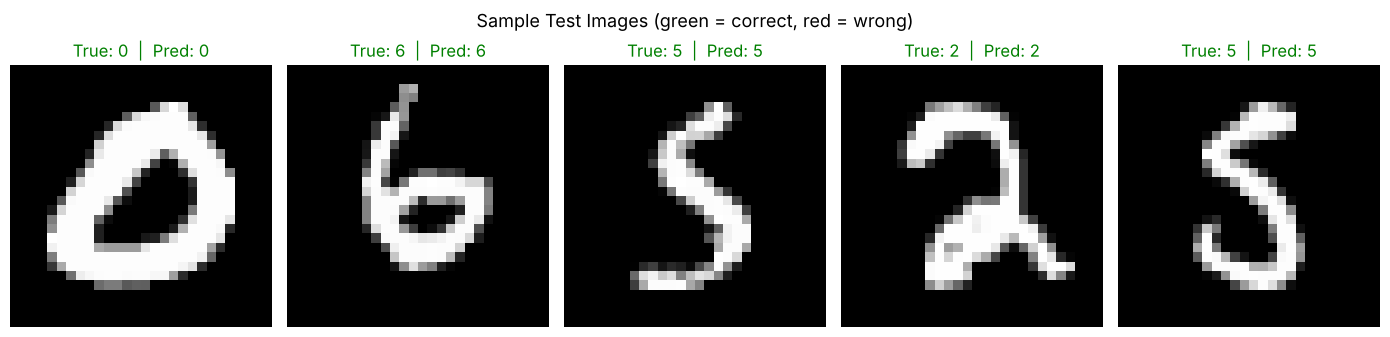

In [9]:
rng = np.random.default_rng(42)
idx = rng.choice(len(X_test), size=5, replace=False)

fig, axes = plt.subplots(1, 5, figsize=(14, 3.5))
for ax, i in zip(axes, idx):
    ax.imshow(X_test[i].reshape(28, 28), cmap='gray')
    correct = y_pred[i] == y_test[i]
    ax.set_title(f'True: {y_test[i]}  |  Pred: {y_pred[i]}', color='green' if correct else 'red', fontsize=12)
    ax.axis('off')
plt.suptitle('Sample Test Images (green = correct, red = wrong)', fontsize=13)
plt.tight_layout()
plt.show()

## Results
- **Final test accuracy: 0.9675** on all 10,000 test images, after training on only 5,000 images for 5 epochs.
- Training accuracy (0.984) and validation accuracy (0.978) are close, so the model is not overfitting much.
- All 5 sample images are predicted correctly.
- The most common mistakes are digits predicted as **8** (e.g. 2→8 and 1→8) and 4↔9 and 7↔2 confusions, which are the digit pairs with the most similar shapes.